importing libraries

In [9]:
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

load dataset

In [10]:
df = pd.read_csv('FakeNewsNet.csv')

print(df.head())
print(df.columns)

                                               title  \
0  Kandi Burruss Explodes Over Rape Accusation on...   
1  People's Choice Awards 2018: The best red carp...   
2  Sophia Bush Sends Sweet Birthday Message to 'O...   
3  Colombian singer Maluma sparks rumours of inap...   
4  Gossip Girl 10 Years Later: How Upper East Sid...   

                                            news_url        source_domain  \
0  http://toofab.com/2017/05/08/real-housewives-a...           toofab.com   
1  https://www.today.com/style/see-people-s-choic...        www.today.com   
2  https://www.etonline.com/news/220806_sophia_bu...     www.etonline.com   
3  https://www.dailymail.co.uk/news/article-33655...  www.dailymail.co.uk   
4  https://www.zerchoo.com/entertainment/gossip-g...      www.zerchoo.com   

   tweet_num  real  
0         42     1  
1          0     1  
2         63     1  
3         20     1  
4         38     1  
Index(['title', 'news_url', 'source_domain', 'tweet_num', 'real'], dtype='

prepare data

In [11]:
X = df['title']
y = df['real']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (18556,)
Testing shape: (4640,)


loading previous trained models rf,svm,dt

In [12]:
svm_model = joblib.load('svm_model.pkl')

dt_model = joblib.load('decision_tree_model.pkl')

rf_model = joblib.load('random_forest_model.pkl')

tfidf = joblib.load('tfidf_vectorizer.pkl')

print("All models loaded successfully!")

All models loaded successfully!


making pred

In [13]:
# SVM
svm_pred = svm_model.predict(X_test)

# Decision Tree
X_test_tfidf = tfidf.transform(X_test)
dt_pred = dt_model.predict(X_test_tfidf)

# Random Forest
rf_pred = rf_model.predict(X_test_tfidf)

print("Predictions completed!")

Predictions completed!


evaluating models

In [14]:
models = {
    'SVM': svm_pred,
    'Decision Tree': dt_pred,
    'Random Forest': rf_pred
}

results = []

for name, pred in models.items():

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1 Score': f1_score(y_test, pred, zero_division=0)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

           Model  Accuracy  Precision  Recall  F1 Score
0            SVM    0.8453     0.8700  0.9338    0.9007
1  Decision Tree    0.8114     0.8240  0.9527    0.8837
2  Random Forest    0.7920     0.7888  0.9880    0.8772


Classification reports

In [15]:
for name, pred in models.items():

    print("\n", name)
    print("=" * 40)

    print(classification_report(
        y_test,
        pred,
        target_names=['Fake', 'Real'],
        zero_division=0
    ))


 SVM
              precision    recall  f1-score   support

        Fake       0.74      0.58      0.65      1151
        Real       0.87      0.93      0.90      3489

    accuracy                           0.85      4640
   macro avg       0.81      0.76      0.77      4640
weighted avg       0.84      0.85      0.84      4640


 Decision Tree
              precision    recall  f1-score   support

        Fake       0.73      0.38      0.50      1151
        Real       0.82      0.95      0.88      3489

    accuracy                           0.81      4640
   macro avg       0.78      0.67      0.69      4640
weighted avg       0.80      0.81      0.79      4640


 Random Forest
              precision    recall  f1-score   support

        Fake       0.84      0.20      0.32      1151
        Real       0.79      0.99      0.88      3489

    accuracy                           0.79      4640
   macro avg       0.82      0.59      0.60      4640
weighted avg       0.80      0.79   

Confusion matrices

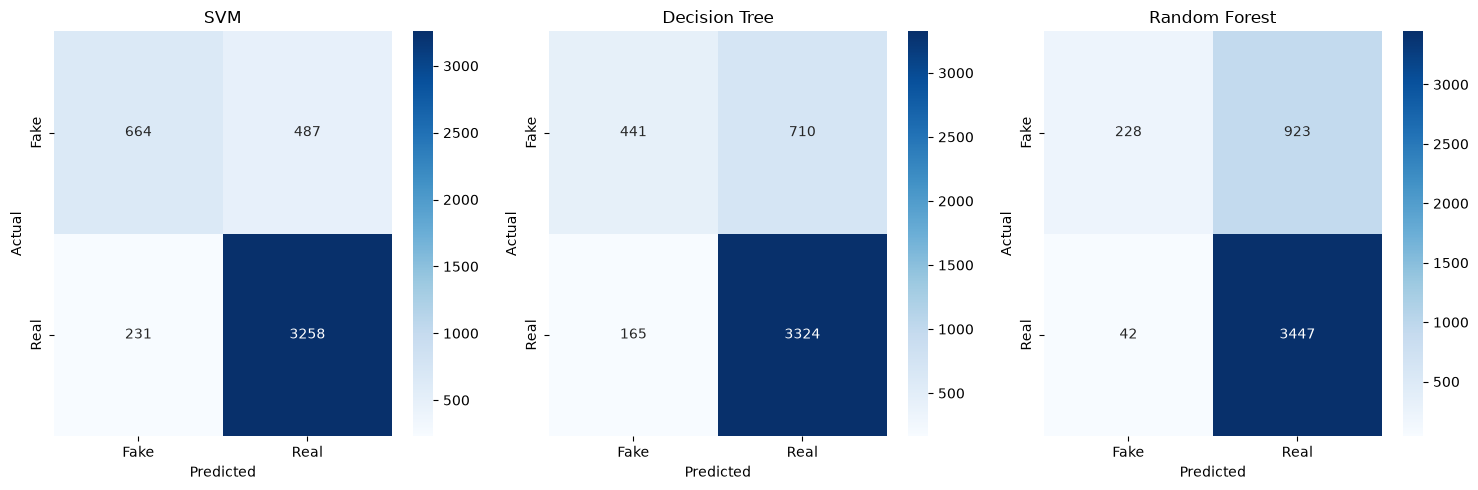

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, pred) in zip(axes, models.items()):

    cm = confusion_matrix(y_test, pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Fake', 'Real'],
        yticklabels=['Fake', 'Real'],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

Performance comparison graph

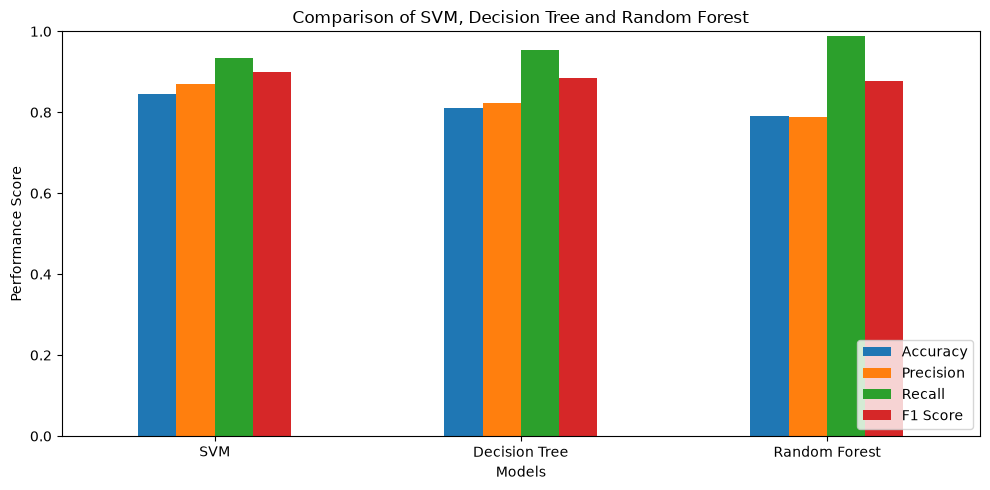

In [17]:
results_df.set_index('Model').plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Comparison of SVM, Decision Tree and Random Forest')
plt.xlabel('Models')
plt.ylabel('Performance Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

Identify the best model

In [18]:
best_model = results_df.loc[
    results_df['F1 Score'].idxmax()
]

print("Best Model:", best_model['Model'])
print("Accuracy:", best_model['Accuracy'])
print("Precision:", best_model['Precision'])
print("Recall:", best_model['Recall'])
print("F1 Score:", best_model['F1 Score'])

Best Model: SVM
Accuracy: 0.8452586206896552
Precision: 0.8699599465954606
Recall: 0.9337919174548581
F1 Score: 0.9007464749792646
